### **Daegu Apartment**

[Data Source Daegu Apartment](https://drive.google.com/file/d/1MPDotXZNmiq6geRi8BkGd-fjttzoyTxW/view?usp=drive_link) 

### **Contents**

1. Business Problem Understanding
2. Data Understanding
3. Data Preprocessing
4. Modeling
5. Conclusion
6. Recommendation

****

### **Business Problem Understanding**

**Context**

The real estate market in urban areas like Daegu, South Korea, faces significant challenges due to limited land availability, high population density, and increasing demand for housing. Apartments are a predominant housing solution, and their pricing is influenced by a complex interplay of internal attributes (e.g., size, age, facilities) and external factors (e.g., proximity to subways, nearby amenities). Property owners and real estate platforms struggle to set optimal listing prices that balance competitiveness and profitability, often leading to suboptimal sales outcomes either prolonged time-on-market or lost revenue.

**Problem Statement**

Property sellers (individuals or agencies) lack an accurate, data-driven method to determine competitive yet profitable apartment prices in Daegu. Current pricing relies heavily on manual appraisal, comparable listings, and intuition, which can result in:

- Overpricing: Apartments remain unsold for extended periods.

- Underpricing: Sellers incur opportunity cost and reduced profit margins.

**This leads to inefficient market transactions, buyer-seller mismatch, and reduced trust in listing platforms.**

**Goals**

Develop a machine learning regression model that:

- Accurately predicts apartment sale prices based on historical transaction data and property features.

- Provides explainable insights into key price drivers (e.g., location, size, accessibility).

- Enables stakeholders (sellers, agents, platforms) to set data-informed listing prices quickly and consistently.

- Improves market efficiency by reducing pricing errors and transaction time.

**Analytic Approach**

| **Step** | **Description** |
| --- | --- |
| Data Collection | Use the provided Daegu apartment dataset with features like Size, YearBuilt, TimeToSubway, etc. |
| Exploratory Data Analysis (EDA) | Visualize distributions, correlations, and outliers. Understand relationships between features and SalePrice. |
| Feature Engineering | Create new predictive features (e.g., Age, TotalFacilitiesNearby, SubwayAccessCategory). |
| Preprocessing | Handle missing values, encode categorical variables, scale numerical features, and split data (train/validation/test). |
| Modeling | Train and compare multiple regression models: Linear Regression, Random Forest, Gradient Boosting (XGBoost/LightGBM). |
| Hyperparameter Tuning | Optimize models using cross-validation (GridSearchCV/RandomizedSearchCV). |
| Interpretation | Use SHAP/LIME for model explainability and identify top price influencers. |

<br>

**Metric Evaluation**

The evaluation metrics used are RMSE, MAE, and MAPE. RMSE is the root mean square error, MAE is the mean absolute error, and MAPE is the mean percentage error generated by the regression model. The smaller the RMSE, MAE, and MAPE values, the more accurate the model is in predicting rental prices, given the feature limitations used.

We can also use the R-squared or adj. R-squared value if the final model is a linear model. The R-squared value is used to determine how well the model represents the overall variance of the data. The closer it is to 1, the better the model fits the observed data. However, this metric is not valid for non-linear models.

### **Data Understanding**



**Attributes Information**

| **Attribute** | **Data Type** | **Description** |
| --- | --- | --- |
| Hallway Type | Object |  Apartment type |
| TimeToSubway | Object | Time needed to the nearest subway station |
| SubwayStation | Object | The name of the nearest subway station |
| N_FacilitiesNearBy(ETC) | Float | The number of facilities nearby |
| N_FacilitiesNearBy(PublicOffice) | Float | The number of public office facilities nearby |
| N_SchoolNearBy(University) | Float | The number of universities nearby |
| N_Parkinglot(Basement) | Float | The number of the parking lot |
| YearBuilt | Integer |  The year the apartment was built |
| N_FacilitiesInApt | Integer | Number of facilities in the apartment  |
| Size(sqft) | Integer | The apartment size (in square feet) |
| SalePrice | Integer | The apartment price (Won) |

<br>

In [1]:
# Import library 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load dataset
df = pd.read_csv('data_daegu_apartment.csv')
df.head()

,HallwayType,TimeToSubway,SubwayStation,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
0,terraced,0-5min,Kyungbuk_uni_hospital,0.0,3.0,2.0,1270.0,2007,10,1387,346017
1,terraced,10min~15min,Kyungbuk_uni_hospital,1.0,5.0,1.0,0.0,1986,4,914,150442
2,mixed,15min~20min,Chil-sung-market,1.0,7.0,3.0,56.0,1997,5,558,61946
3,mixed,5min~10min,Bangoge,5.0,5.0,4.0,798.0,2005,7,914,165486
4,terraced,0-5min,Sin-nam,0.0,1.0,2.0,536.0,2006,5,1743,311504


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4123 entries, 0 to 4122
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HallwayType                       4123 non-null   object 
 1   TimeToSubway                      4123 non-null   object 
 2   SubwayStation                     4123 non-null   object 
 3   N_FacilitiesNearBy(ETC)           4123 non-null   float64
 4   N_FacilitiesNearBy(PublicOffice)  4123 non-null   float64
 5   N_SchoolNearBy(University)        4123 non-null   float64
 6   N_Parkinglot(Basement)            4123 non-null   float64
 7   YearBuilt                         4123 non-null   int64  
 8   N_FacilitiesInApt                 4123 non-null   int64  
 9   Size(sqf)                         4123 non-null   int64  
 10  SalePrice                         4123 non-null   int64  
dtypes: float64(4), int64(4), object(3)
memory usage: 354.4+ KB


#### **Exploratory Data Analysis**

In [4]:
print("\nColumn Data Type Identification:")
for col in df.columns:
    dtype = df[col].dtype
    unique_count = df[col].nunique()
    print(f"{col}: {dtype}, Unique values: {unique_count}")


Column Data Type Identification:
HallwayType: object, Unique values: 3
TimeToSubway: object, Unique values: 5
SubwayStation: object, Unique values: 8
N_FacilitiesNearBy(ETC): float64, Unique values: 4
N_FacilitiesNearBy(PublicOffice): float64, Unique values: 8
N_SchoolNearBy(University): float64, Unique values: 6
N_Parkinglot(Basement): float64, Unique values: 20
YearBuilt: int64, Unique values: 16
N_FacilitiesInApt: int64, Unique values: 9
Size(sqf): int64, Unique values: 89
SalePrice: int64, Unique values: 838


**Distribution of Daegu Apartment Price**
***Target Variable***

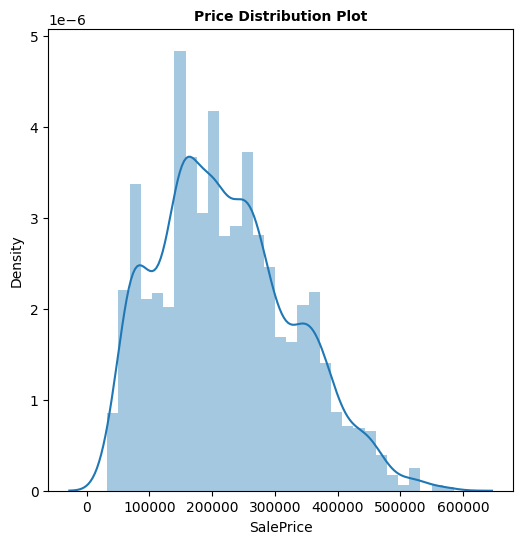

In [5]:
# Plot Distribution 'price' feature
plt.figure(figsize=(6, 6))
sns.distplot(df['SalePrice'])
plt.title('Price Distribution Plot', size=10, weight='bold');

Based on the Daegu apartment price distribution plot above, it appears to have a right-skewed distribution. In other words, there is positive skewness in the price feature.

**Categorical Variable Analysis ('HallwayType' , 'TimeToSubway', 'SubwayStatiion')**

In [6]:
categorical_cols = ['HallwayType', 'TimeToSubway', 'SubwayStation']
print("\n Categorical Column Analysis:")
for col in categorical_cols:
    if col in df.columns:
        print(f"\n{col} ({df[col].dtype}), ({df[col].nunique()} unique values):")
        print(f"Distribusi:")
        print(f"{df[col].value_counts()}")
        
    else:
        print(f"\n Kolom {col} tidak ditemukan dalam dataset")


 Categorical Column Analysis:

HallwayType (object), (3 unique values):
Distribusi:
HallwayType
terraced    2528
mixed       1131
corridor     464
Name: count, dtype: int64

TimeToSubway (object), (5 unique values):
Distribusi:
TimeToSubway
0-5min                1953
5min~10min             787
15min~20min            629
10min~15min            583
no_bus_stop_nearby     171
Name: count, dtype: int64

SubwayStation (object), (8 unique values):
Distribusi:
SubwayStation
Kyungbuk_uni_hospital    1152
Myung-duk                1044
Banwoldang                529
Bangoge                   502
Sin-nam                   467
no_subway_nearby          290
Chil-sung-market           74
Daegu                      65
Name: count, dtype: int64


In [7]:
df.groupby(['SubwayStation', 'HallwayType'])['HallwayType'].count()

SubwayStation          HallwayType
Bangoge                mixed           502
Banwoldang             corridor         50
                       terraced        479
Chil-sung-market       mixed            74
Daegu                  corridor         51
                       terraced         14
Kyungbuk_uni_hospital  corridor         49
                       terraced       1103
Myung-duk              corridor        222
                       mixed           555
                       terraced        267
Sin-nam                corridor         51
                       terraced        416
no_subway_nearby       corridor         41
                       terraced        249
Name: HallwayType, dtype: int64

Categorical Columns Distribution:


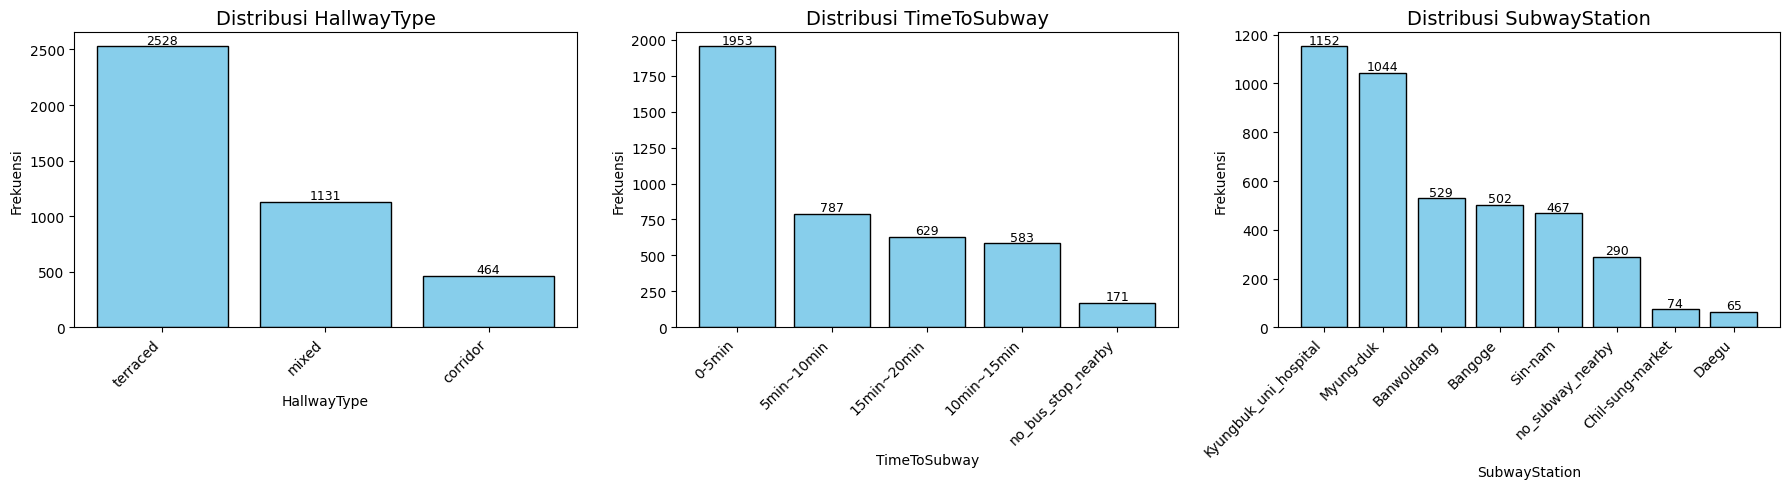

In [8]:
print("Categorical Columns Distribution:")

if len(categorical_cols) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for idx, col in enumerate(categorical_cols):
        if col in df.columns and idx < 3:
            value_counts = df[col].value_counts()
            
            axes[idx].bar(range(len(value_counts)), value_counts.values, color='skyblue', edgecolor='black')
            axes[idx].set_title(f'Distribusi {col}', fontsize=14)
            axes[idx].set_xlabel(col)
            axes[idx].set_ylabel('Frekuensi')
            axes[idx].set_xticks(range(len(value_counts)))
            axes[idx].set_xticklabels(value_counts.index, rotation=45, ha='right')
            
            for i, v in enumerate(value_counts.values):
                axes[idx].text(i, v + max(value_counts.values)*0.01, str(v), 
                              ha='center', fontsize=9)
    
    plt.tight_layout()
    plt.show()

**Interpretation for Categorical Variable Analysis**
***HallwayType, TimeToSubway, SubwayStation***

- Residences tend to be located in locations with very close transportation access.
- Certain building designs (terraced) are more dominant.
- Properties are concentrated around certain stations, which are likely to be the center of city activity.

In [9]:
df[categorical_cols].describe()

,HallwayType,TimeToSubway,SubwayStation
count,4123,4123,4123
unique,3,5,8
top,terraced,0-5min,Kyungbuk_uni_hospital
freq,2528,1953,1152


Price Distribution by ***HallwayType, TimeToSubway, SubwayStation***

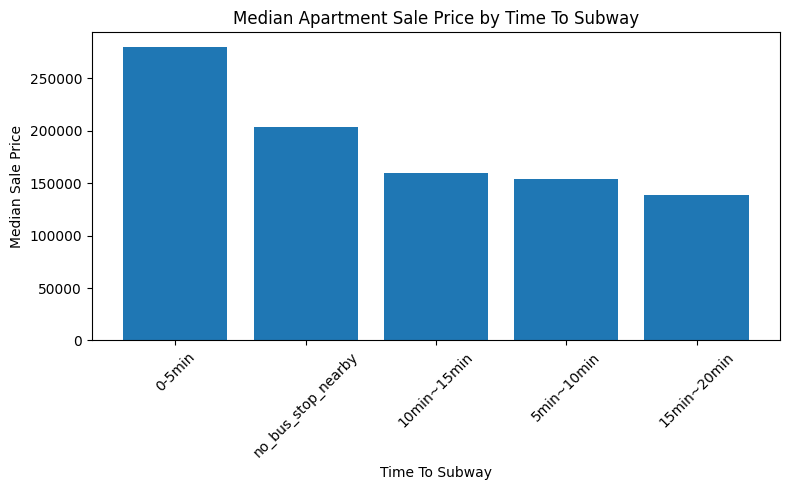

In [10]:
df_median_price = df.groupby(by=['TimeToSubway']).agg({'SalePrice':'median'}).reset_index()
df_median_price = df_median_price.set_index('TimeToSubway')
df_median_price = df_median_price.sort_values('SalePrice', ascending =False)
df_median_price.head()

plt.figure(figsize=(8,5))

plt.bar(df_median_price.index, df_median_price['SalePrice'])

plt.xlabel('Time To Subway')
plt.ylabel('Median Sale Price')
plt.title('Median Apartment Sale Price by Time To Subway')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

🎯 Key Insights
- Access ≤ 5 minutes incurs a significant price premium
Difference between:
0–5 min (280k)
15–20 min (140k)
Almost double the price.
This indicates:
TimeToSubway is a feature with a strong influence on SalePrice.

- Decreasing pattern (negative relationship)
The longer the travel time, the lower the price.
This means:
There is a negative correlation between distance/time to the subway and SalePrice.
**This feature is very suitable for inclusion in the model.**

- A small anomaly
10–15 min is slightly higher than 5–10 min (a small difference).
Possibility:
Uneven sample size
Certain locations have other factors (e.g., amenities, size)

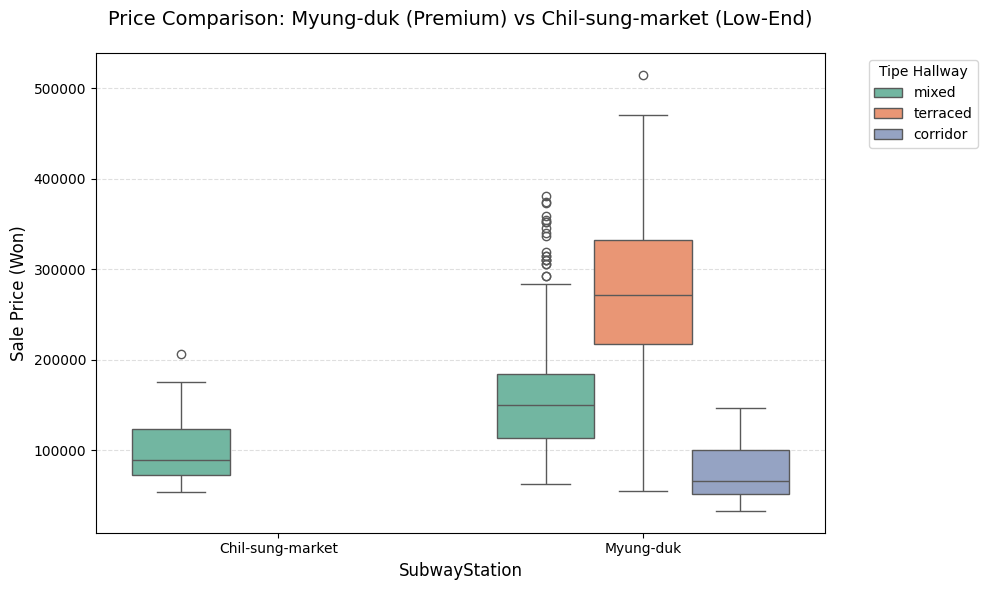

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Filtering data hanya untuk dua stasiun (pastikan penulisan sesuai dengan isi dataset)
# Berdasarkan slide Anda, penulisannya adalah 'Myung-duk' dan 'Chil-sung-market'
target_stations = ['Myung-duk', 'Chil-sung-market']
df_filtered = df[df['SubwayStation'].isin(target_stations)]

# 2. Setup visualisasi
plt.figure(figsize=(10, 6))

# 3. Membuat Boxplot
sns.boxplot(
    data=df_filtered, 
    x='SubwayStation', 
    y='SalePrice', 
    hue='HallwayType',
    palette='Set2' # Palet warna yang bersih dan profesional
)

# 4. Professional Formatting
plt.title('Price Comparison: Myung-duk (Premium) vs Chil-sung-market (Low-End)', fontsize=14, pad=20)
plt.xlabel('SubwayStation', fontsize=12)
plt.ylabel('Sale Price (Won)', fontsize=12)

# Tambahkan grid transparan pada sumbu Y untuk mempermudah perbandingan harga
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Rapikan posisi legend
plt.legend(title='Tipe Hallway', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

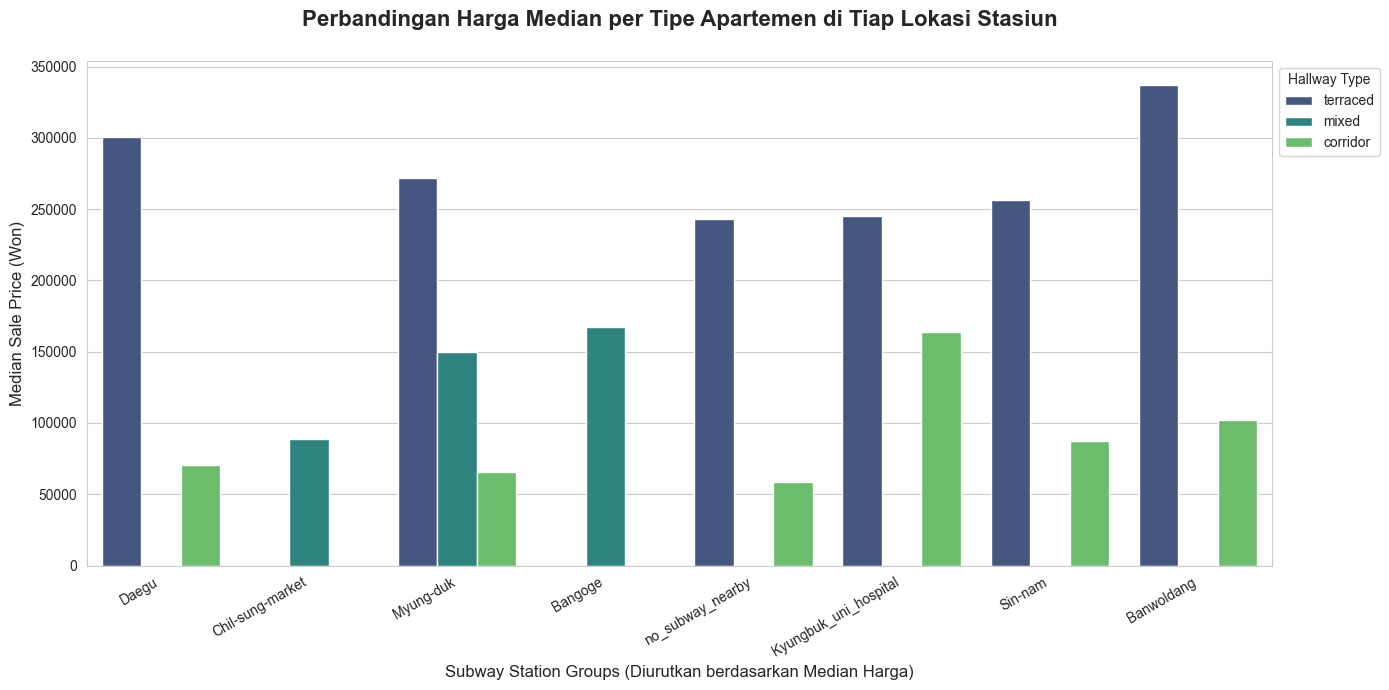

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Mengatur urutan stasiun berdasarkan median harga (agar grafik bercerita dari harga terendah ke tertinggi)
order = df.groupby('SubwayStation')['SalePrice'].median().sort_values().index

# 2. Setup visualisasi
plt.figure(figsize=(14, 7))
sns.set_style("whitegrid") # Menggunakan grid putih agar terlihat bersih

# 3. Membuat Grouped Bar Chart
# estimator=np.median artinya kita menampilkan nilai tengah
# errorbar=None untuk menghilangkan garis ketidakpastian agar grafik lebih "clean" untuk presentasi
plot = sns.barplot(
    data=df, 
    x='SubwayStation', 
    y='SalePrice', 
    hue='HallwayType', 
    order=order,
    estimator=np.median, 
    errorbar=None,
    palette='viridis'
)

# 4. Professional Styling
plt.title('Perbandingan Harga Median per Tipe Apartemen di Tiap Lokasi Stasiun', fontsize=16, pad=25, fontweight='bold')
plt.xlabel('Subway Station Groups (Diurutkan berdasarkan Median Harga)', fontsize=12)
plt.ylabel('Median Sale Price (Won)', fontsize=12)

# Rotasi label agar tidak bertabrakan
plt.xticks(rotation=30, ha='right')

# Merapikan Legend
plt.legend(title='Hallway Type', bbox_to_anchor=(1, 1), loc='upper left', frameon=True)

# Menambahkan label angka di atas bar (Opsional, gunakan jika audiens butuh angka presisi)
# for i in plot.containers:
#    plot.bar_label(i, fmt='%.0f', padding=3, rotation=90, fontsize=8)

plt.tight_layout()
plt.show()

HallwayType,corridor,mixed,terraced
SubwayStation,,,
Bangoge,NaN,167035.0,NaN
Banwoldang,101769.0,NaN,337168.0
Chil-sung-market,NaN,88495.0,NaN
Daegu,70796.0,NaN,300884.0
Kyungbuk_uni_hospital,163716.0,NaN,244911.0
Myung-duk,65486.0,149557.0,271681.0
Sin-nam,87610.0,NaN,256637.0
no_subway_nearby,58407.0,NaN,243362.0


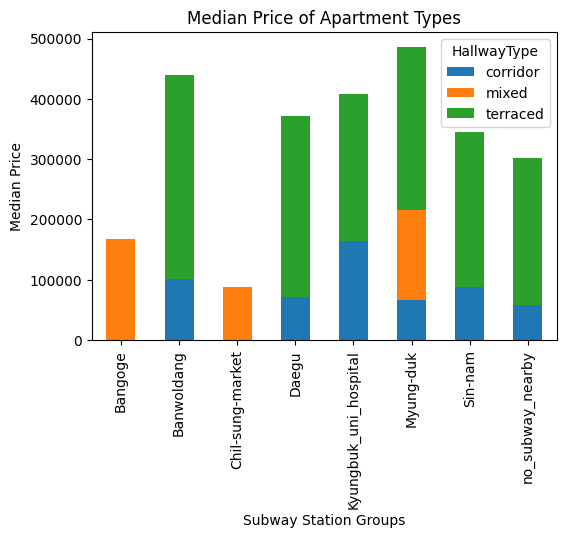

In [11]:
from IPython.display import display
station_pivot = df.pivot_table(index='SubwayStation', columns='HallwayType', values='SalePrice', aggfunc='median')
display(station_pivot)

pivot_plot = station_pivot.plot.bar(stacked=True, figsize=(6, 4))
pivot_plot.set_xlabel('Subway Station Groups')
pivot_plot.set_ylabel('Median Price')
pivot_plot.set_title('Median Price of Apartment Types');

Median Price of Apartment Types (per Subway Station Group & Hallway Type)

🔎 Key Insights
- The "terraced" hallway type is consistently the most expensive. 
    In almost all locations (Banwoldang, Daegu, Myung-duk, etc.), terraced consistently has the highest median price. A rough example from the graph: Banwoldang (terraced) ≈ 440,000, Myung-duk (terraced) ≈ 490,000 (highest in the graph)

    Insight:
    The structure or layout of an apartment significantly influences price.
    Terraced apartments are likely perceived as: More private, More spacious, More premium
    This shows that Hallway Type is an important feature in modeling.

- Subway location also has a significant impact.

    Locations with the highest median price: Myung-duk, Banwoldang, Kyungbuk_uni_hospital

    Locations with lower median prices: no_subway_nearby, Sin-nam

    Insight:

    Accessibility and location prestige clearly impact price.

- Most expensive combination

    Terraced + strategic location (Myung-duk / Banwoldang)

    Meaning:

    There is a possible interaction between the Location × HallwayType features.

    For advanced modeling, consider:

    Feature interaction

    Target encoding per combination

**Numerical Variabel Analysis**

Numeric Columns Distribution:


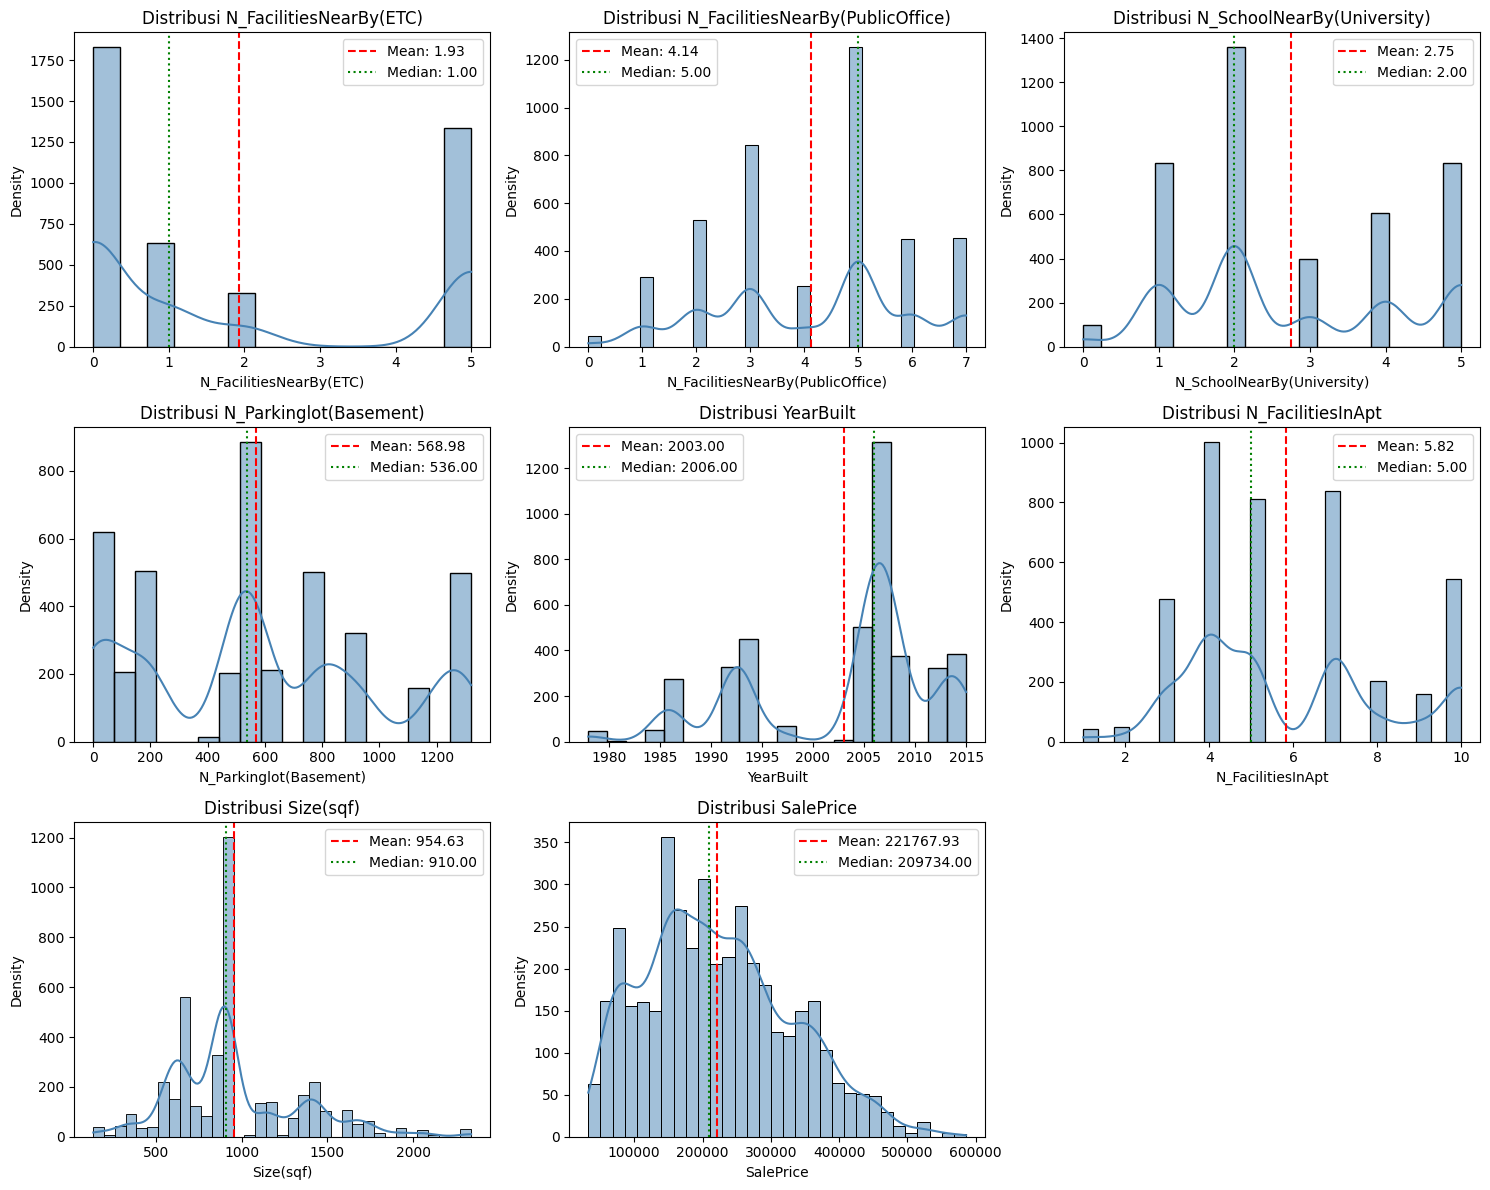

In [12]:
numerical_cols = numerical_cols = df.select_dtypes(include=[np.number]).columns
if len(numerical_cols) > 0:
    print("Numeric Columns Distribution:")
    
    n_cols = 3
    n_rows = int(np.ceil(len(numerical_cols) / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
    
    if len(numerical_cols) == 1:
        axes = [axes]
    elif n_rows > 1 and n_cols > 1:
        axes = axes.flatten()
    
    for idx, col in enumerate(numerical_cols):
        if idx < len(axes):
            sns.histplot(df[col], kde=True, ax=axes[idx], color='steelblue')
            axes[idx].set_title(f'Distribusi {col}', fontsize=12)
            axes[idx].set_xlabel(col)
            axes[idx].set_ylabel('Density')
            
            axes[idx].axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.2f}')
            axes[idx].axvline(df[col].median(), color='green', linestyle=':', label=f'Median: {df[col].median():.2f}')
            axes[idx].legend()
    
    for idx in range(len(numerical_cols), len(axes)):
        axes[idx].set_visible(False)
    
    plt.tight_layout()
    plt.show()

In [13]:
df[numerical_cols].describe()

,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
count,4123.000000,4123.000000,4123.000000,4123.000000,4123.000000,4123.000000,4123.000000,4123.000000
mean,1.930876,4.135338,2.746301,568.979141,2002.999757,5.817851,954.630851,221767.926995
std,2.198832,1.802640,1.496610,410.372742,8.905768,2.340507,383.805648,106739.839945
min,0.000000,0.000000,0.000000,0.000000,1978.000000,1.000000,135.000000,32743.000000
25%,0.000000,3.000000,2.000000,184.000000,1993.000000,4.000000,644.000000,144752.000000
50%,1.000000,5.000000,2.000000,536.000000,2006.000000,5.000000,910.000000,209734.000000
75%,5.000000,5.000000,4.000000,798.000000,2008.000000,7.000000,1149.000000,291150.000000
max,5.000000,7.000000,5.000000,1321.000000,2015.000000,10.000000,2337.000000,585840.000000


1. N_FacilitiesNearBy (ETC)

* Mean = 1.93 | Median = 1.00 
* Mean > median → right-skewed (positively skewed) 
* Many properties have 0–1 amenities, but a small percentage with high scores (4–5) push the mean upward.

--> This means that most apartments have few additional public amenities, but there are small clusters with very comprehensive amenities.

---
2️. N_FacilitiesNearBy (PublicOffice)

* Mean = 4.14 | Median = 5.00 
* Median > mean → slightly left-skewed 
* The distribution is relatively even at 3–6.

--> This means that the majority of apartments are located in areas with relatively high access to public offices (around 5).

---

3. N_SchoolNearBy (University)

* Mean = 2.75 | Median = 2.00
* Mean > median → **slight right-skewed**
* Many properties are near 1–2 universities, few are very numerous (4–5).

--> Areas with a high concentration of universities are only a small fraction.

---

4️. N_Parkinglot (Basement)

* Mean = 568.98 | Median = 536.00
* Nearly symmetrical, but slightly right-skewed
* Very wide range (0–1300+)

--> There is a large variation in parking capacity → likely influenced by the size of the apartment complex.

---
5️.  YearBuilt

* Mean = 2003 | Median = 2006
* Median > mean → slightly **left-skewed**
* Many buildings after 2000.

--> The property stock is relatively modern. Some older buildings (1980–1990) lower the mean.

---

6️. N_FacilitiesInApt

* Mean = 5.82 | Median = 5.00
* Slightly right-skewed
* The majority have 4–6 internal facilities.

--> There are some premium apartments with significantly more facilities.

---

7️. Size (sqf)

* Mean = 954.63 | Median = 910.00
* Mean > median → **right-skewed**
* The majority of units are around 700–1100 sqf, but there are large units (>1500 sqf).

--> There are high-end properties that increase the average.

---

8️. SalePrice

* Mean = 221,767 | Median = 209,734
* Mean > median → **quite strongly right-skewed**
* Tail extension up to ~600k.

--> The market has some significantly expensive properties → prices are not normally distributed.

### **Data Preprocessing**

At this stage, we will clean the data, which we will then use for the next analysis process. Some things to do are:
- Drop features that are irrelevant to the problem at hand.
- Treat missing values, if any. This can be done by dropping the feature if it's not needed or by imputing the most reasonable value based on the case.
- Checking and handling outliers if it's possible.

For data preprocessing and feature engineering, we will use a dataframe that is a duplicate of the previously used dataframe.

In [14]:
df_model = df.copy()

Check the detail information for every features.

In [15]:
listItem = []

for col in df_model.columns:
    listItem.append([col, df_model[col].dtype, df_model[col].isna().sum(), round((df_model[col].isna().sum()/len(df_model[col]))*100, 2),
                    df_model[col].nunique(), list(df_model[col].drop_duplicates().sample(2).values)]);

df_model_desc = pd.DataFrame(columns=['dataFeatures', 'dataType', 'null', 'nullPct', 'unique', 'uniqueSample'],
                     data=listItem)
df_model_desc

,dataFeatures,dataType,null,nullPct,unique,uniqueSample
0,HallwayType,object,0,0.0,3,"[corridor, terraced]"
1,TimeToSubway,object,0,0.0,5,"[10min~15min, 0-5min]"
2,SubwayStation,object,0,0.0,8,"[Sin-nam, Kyungbuk_uni_hospital]"
3,N_FacilitiesNearBy(ETC),float64,0,0.0,4,"[1.0, 0.0]"
4,N_FacilitiesNearBy(PublicOffice),float64,0,0.0,8,"[0.0, 2.0]"
5,N_SchoolNearBy(University),float64,0,0.0,6,"[0.0, 1.0]"
6,N_Parkinglot(Basement),float64,0,0.0,20,"[79.0, 56.0]"
7,YearBuilt,int64,0,0.0,16,"[2007, 1997]"
8,N_FacilitiesInApt,int64,0,0.0,9,"[5, 3]"
9,Size(sqf),int64,0,0.0,89,"[1327, 811]"


From the dataset info above, it is known that there is no empty data in the features or columns.

We can also determine that there are no duplicates in the dataset by looking at the number of unique entries in the id feature, which equals the total number of entries. Therefore, this dataset contains 1422 duplicates. To confirm this, we can check using the duplicated() function.

In [16]:
df_model.duplicated().sum()

np.int64(1422)

**Remove Duplicates**

In [17]:
df_model.drop_duplicates(inplace=True)
print(df_model.duplicated().sum())

0


In [18]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2701 entries, 0 to 4121
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HallwayType                       2701 non-null   object 
 1   TimeToSubway                      2701 non-null   object 
 2   SubwayStation                     2701 non-null   object 
 3   N_FacilitiesNearBy(ETC)           2701 non-null   float64
 4   N_FacilitiesNearBy(PublicOffice)  2701 non-null   float64
 5   N_SchoolNearBy(University)        2701 non-null   float64
 6   N_Parkinglot(Basement)            2701 non-null   float64
 7   YearBuilt                         2701 non-null   int64  
 8   N_FacilitiesInApt                 2701 non-null   int64  
 9   Size(sqf)                         2701 non-null   int64  
 10  SalePrice                         2701 non-null   int64  
dtypes: float64(4), int64(4), object(3)
memory usage: 253.2+ KB


In [19]:
num_features = [feature for feature in df_model.columns if ((df_model[feature].dtypes != 'object'))]
df_model[num_features].describe()

,N_FacilitiesNearBy(ETC),N_FacilitiesNearBy(PublicOffice),N_SchoolNearBy(University),N_Parkinglot(Basement),YearBuilt,N_FacilitiesInApt,Size(sqf),SalePrice
count,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000,2701.000000
mean,1.890411,4.027027,2.680489,533.746390,2002.358386,5.713439,984.028878,229511.365790
std,2.153168,1.887486,1.504470,418.224859,9.151949,2.386552,391.982619,105079.891321
min,0.000000,0.000000,0.000000,0.000000,1978.000000,1.000000,135.000000,32743.000000
25%,0.000000,3.000000,2.000000,181.000000,1993.000000,4.000000,743.000000,153539.000000
50%,1.000000,4.000000,2.000000,536.000000,2006.000000,5.000000,910.000000,221238.000000
75%,5.000000,5.000000,4.000000,798.000000,2007.000000,7.000000,1167.000000,300884.000000
max,5.000000,7.000000,5.000000,1321.000000,2015.000000,10.000000,2337.000000,585840.000000


🎯 Brief Summary of Data Condition

- The dataset is relatively clean (no illogical extreme values).

- The main numeric variables (SalePrice & Size) have a right-skewed distribution.

- There are possible natural outliers (premium apartments).

- There are no visible data errors (e.g., the year 1800, negative size, etc.).

Next, we'll examine the data distribution and outliers for each numerical feature. If the distribution has high skewness, one way to reduce it is by engineering each feature.

**Outliers Detection**

The number of outliers in the data will certainly affect the analysis and modeling results. Several factors must be considered before deciding on an appropriate treatment for the data, including domain knowledge.


Outliers Detection with IQR Method:
Size(sqf): 98 outliers (2.38%)
SalePrice: 27 outliers (0.65%)

 Outliers Detail:
  Feature  Outliers  Percentage (%)  Lower Bound  Upper Bound
Size(sqf)        98        2.376910       -113.5       1906.5
SalePrice        27        0.654863     -74845.0     510747.0


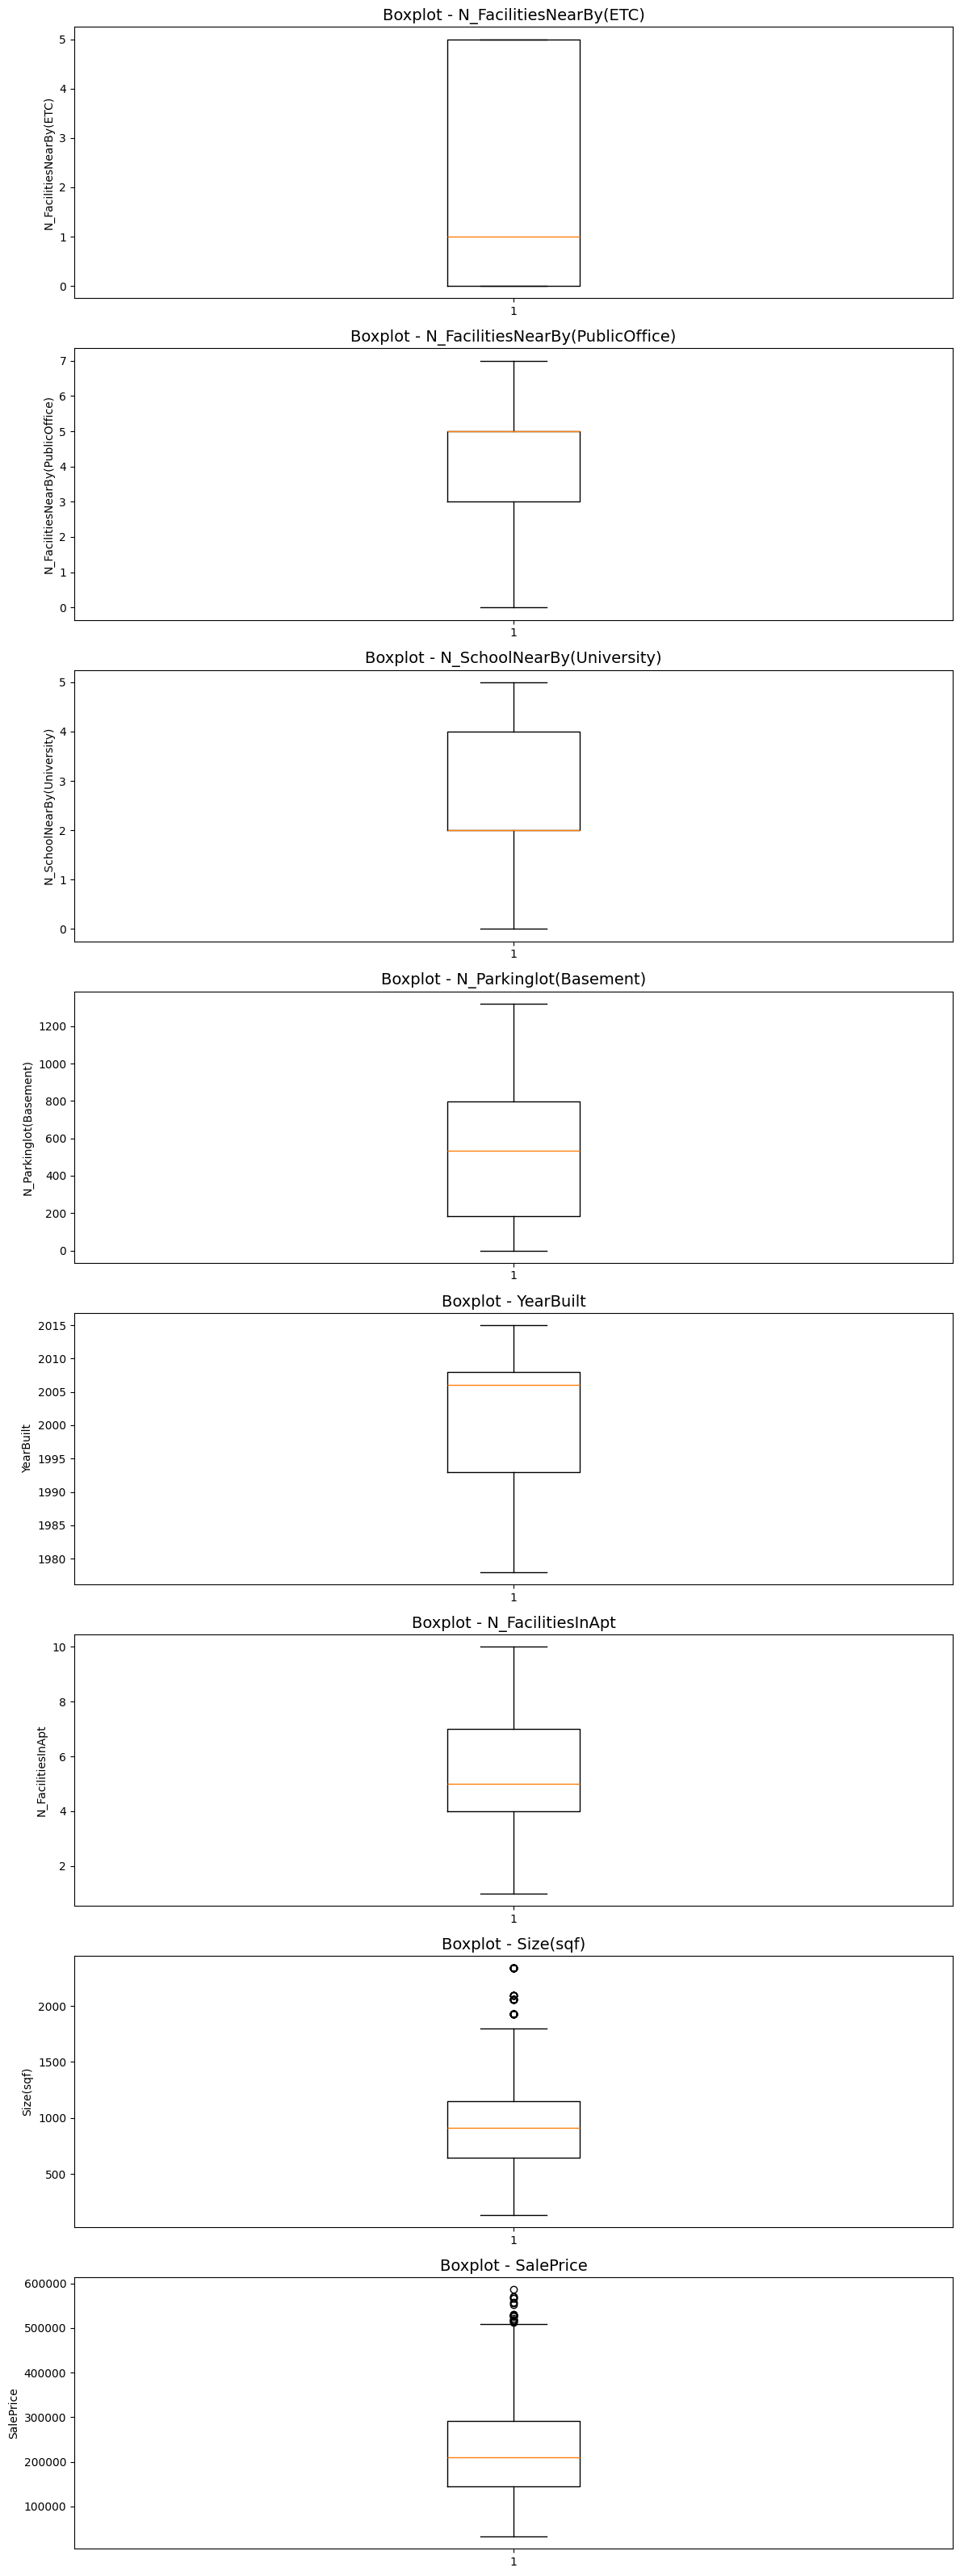

In [20]:
numerical_cols = df_model.select_dtypes(include=[np.number]).columns
print("\nOutliers Detection with IQR Method:")
outliers_info = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_count = len(outliers)
    outlier_percentage = (outlier_count / len(df)) * 100
    
    if outlier_count > 0:
        outliers_info.append({
            'Feature': col,
            'Outliers': outlier_count,
            'Percentage (%)': outlier_percentage,
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound
        })
        print(f"{col}: {outlier_count} outliers ({outlier_percentage:.2f}%)")

if outliers_info:
    outliers_df = pd.DataFrame(outliers_info)
    print("\n Outliers Detail:")
    print(outliers_df.to_string(index=False))

if numerical_cols.size > 0:
    fig, axes = plt.subplots(len(numerical_cols), 1, figsize=(12, 4*len(numerical_cols)))
    
    if len(numerical_cols) == 1:
        axes = [axes]
    
    for idx, col in enumerate(numerical_cols):
        axes[idx].boxplot(df[col].dropna())
        axes[idx].set_title(f'Boxplot - {col}', fontsize=14)
        axes[idx].set_ylabel(col)
    
    plt.tight_layout()
    plt.show()

Based on the analysis results, it can be seen that after detection, only two variables were detected as containing outliers, namely the variables 'SalePrice' and 'Size'. The percentage of the variables is also still categorized as mild (<5%). Furthermore, the outlier values ​​are not extreme and are still very reasonable, so they do not need to be removed.

**Data Correlation**


Matrix Correlation:


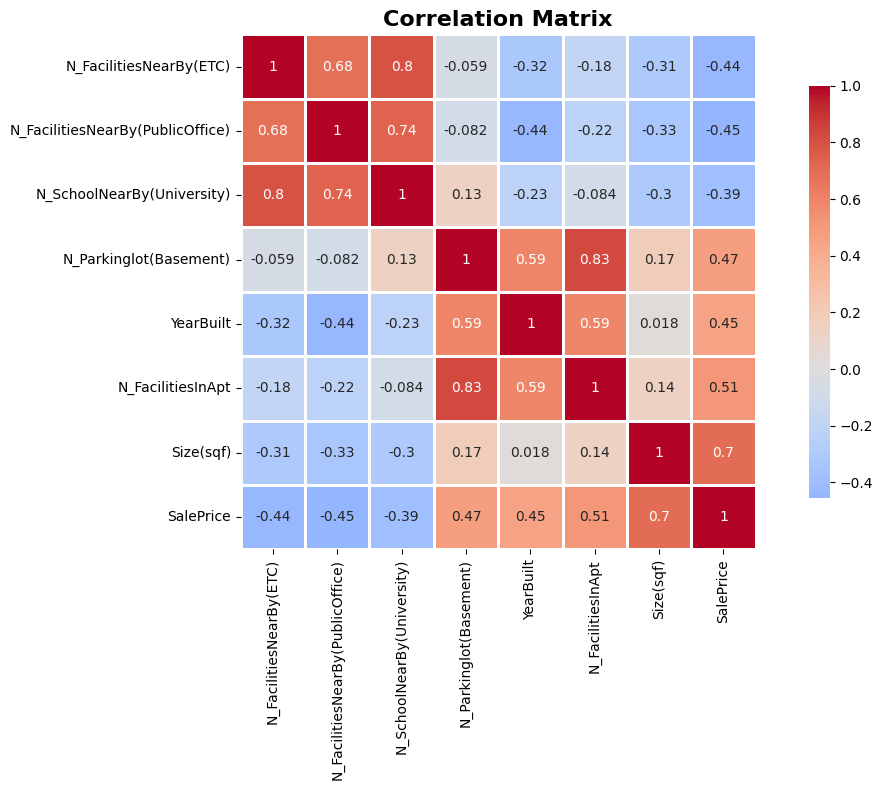


 Correlation with SalePrice:
SalePrice                           1.000000
Size(sqf)                           0.697685
N_FacilitiesInApt                   0.509327
N_Parkinglot(Basement)              0.472419
YearBuilt                           0.446278
N_SchoolNearBy(University)         -0.393332
N_FacilitiesNearBy(ETC)            -0.439968
N_FacilitiesNearBy(PublicOffice)   -0.454402
Name: SalePrice, dtype: float64


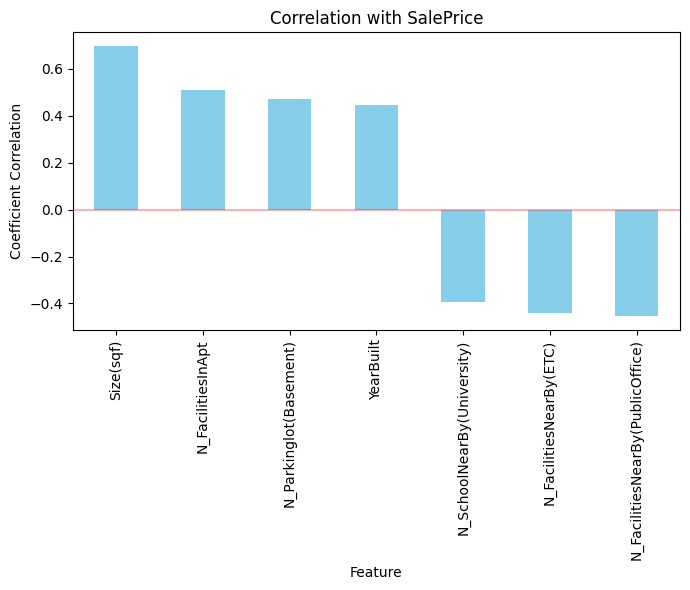

In [21]:
print("\nMatrix Correlation:")
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

if 'SalePrice' in df.columns:
    print("\n Correlation with SalePrice:")
    price_corr = correlation_matrix['SalePrice'].sort_values(ascending=False)
    print(price_corr)
    
    plt.figure(figsize=(7, 6))
    price_corr.drop('SalePrice').plot(kind='bar', color='skyblue')
    plt.title('Correlation with SalePrice', fontsize=12)
    plt.xlabel('Feature')
    plt.ylabel('Coefficient Correlation')
    plt.axhline(y=0, color='r', linestyle='-', alpha=0.3)
    plt.tight_layout()
    plt.show()

💰 Interpretation of Correlation to `Sale Price`
- Size (sqf) → 0.697685 Correlation: Strong (positive)
This means: the larger the apartment area, the higher the selling price.
This is the most relevant feature in this data.
A value of 0.69 approaching 0.70 → is very practically significant.
Relevance: Very High (Main feature determining price)

- N_FacilitiesInApt → 0.509327 Correlation: Moderate (positive)
The more amenities in an apartment (gym, elevator, etc.), the higher the price.
A value of 0.50 indicates a moderately significant influence, although not as strong as size.
Relevance: High – a factor that increases property value

- N_Parkinglot (Basement) → 0.472419 Correlation: Moderate (positive)
The more basement parking spaces, the higher the price.
This makes sense because parking increases convenience and resale value.
Relevance: Fairly High – a contributing factor to value

- Year Built → 0.446278 Correlation: Medium (positive)
The newer the apartment, the higher the price.
Newer properties are usually more modern and require less renovation costs.
Relevance: Fairly High – building age matters

- N_SchoolNearBy (University) → -0.393332 Correlation: Weak–Medium (negative)
The more universities nearby, the lower the price.
Possible interpretations:
Campus areas are synonymous with student housing (cheaper)
Crowder neighborhoods → less exclusive
Relevance: Medium (moderate negative effect)

- N_FacilitiesNearBy (ETC) → -0.439968 Correlation: Medium (negative)
The more public facilities nearby, the lower the price.
Possibility:
The area is too commercial
High noise level
Relevance: Fairly High (significant negative effect)

- N_FacilitiesNearBy (PublicOffice) → -0.454402 Correlation: Moderate (negative)
The more government offices nearby, the lower the price tends to be.
This could be due to:
Administrative area, not premium residential, High traffic
Relevance: Fairly High (significant negative effect)

**Features Engineering & Features Selection**

Based on domain knowledge and the correlation between the feature variables and the target variable.

We can also modify the 'YearBuilt' feature by changing it to the more relevant 'AgeApartment'.

Furthermore, the three features with the lowest correlations, 'N_FacilitiesNearBy(ETC)', 'N_FacilitiesNearBy(PublicOffice)', and 'N_SchoolNearBy(University),' can be considered for combining them into a single feature, 'TotalFacilitiesNearby'.

In [22]:
from datetime import date

In [23]:
current_year = date.today().year
df_model['AgeApartment'] = current_year - df_model['YearBuilt']

df_model.drop(columns=['YearBuilt'], inplace=True)

In [24]:
facilities_cols = [
    'N_FacilitiesNearBy(ETC)', 
    'N_FacilitiesNearBy(PublicOffice)', 
    'N_SchoolNearBy(University)'
]

df_model['TotalFacilitiesNearby'] = df_model[facilities_cols].sum(axis=1)

df_model.drop(columns=facilities_cols, inplace=True)

***Size_Terraced_Interaction***

The Reason: To capture the non-linear value premium of specific architectural designs.

Business Logic: In real estate, the value of a specific "hallway type" (like terraced) is rarely constant. A large apartment in a terraced building is often exponentially more valuable than a small one in the same building because "terraced" designs are typically associated with luxury or premium penthouses.

In [25]:
df_model['Size_Terraced_Interaction'] = df_model.apply(
    lambda x: x['Size(sqf)'] if x['HallwayType'] == 'terraced' else 0, axis=1
)

***Parking_Ratio***

The Reason: To measure "Infrastructure Adequacy" and "Serviceability Density."

Business Logic: Raw numbers can be misleading. A building with 100 parking spots might sound good, but if that building also has 50 different facilities (gyms, pools, shops), those 100 spots will be crowded. A high ratio of parking to facilities indicates a well-planned, high-end complex where convenience is prioritized.

In [26]:
df_model['Parking_Ratio'] = df_model['N_Parkinglot(Basement)'] / df_model['N_FacilitiesInApt']

In [27]:
print("Cleaned Dataset Preview:")
print(df_model.head())

print("\nNew Columns in Dataset:")
print(df_model.columns.tolist())

Cleaned Dataset Preview:
  HallwayType TimeToSubway          SubwayStation  N_Parkinglot(Basement)  \
0    terraced       0-5min  Kyungbuk_uni_hospital                  1270.0   
1    terraced  10min~15min  Kyungbuk_uni_hospital                     0.0   
2       mixed  15min~20min       Chil-sung-market                    56.0   
3       mixed   5min~10min                Bangoge                   798.0   
4    terraced       0-5min                Sin-nam                   536.0   

   N_FacilitiesInApt  Size(sqf)  SalePrice  AgeApartment  \
0                 10       1387     346017            19   
1                  4        914     150442            40   
2                  5        558      61946            29   
3                  7        914     165486            21   
4                  5       1743     311504            20   

   TotalFacilitiesNearby  Size_Terraced_Interaction  Parking_Ratio  
0                    5.0                       1387          127.0  
1            

**Clean Dataset**

In [28]:
# Clean Dataset Preview
df_model.head()

,HallwayType,TimeToSubway,SubwayStation,N_Parkinglot(Basement),N_FacilitiesInApt,Size(sqf),SalePrice,AgeApartment,TotalFacilitiesNearby,Size_Terraced_Interaction,Parking_Ratio
0,terraced,0-5min,Kyungbuk_uni_hospital,1270.0,10,1387,346017,19,5.0,1387,127.0
1,terraced,10min~15min,Kyungbuk_uni_hospital,0.0,4,914,150442,40,7.0,914,0.0
2,mixed,15min~20min,Chil-sung-market,56.0,5,558,61946,29,11.0,0,11.2
3,mixed,5min~10min,Bangoge,798.0,7,914,165486,21,14.0,0,114.0
4,terraced,0-5min,Sin-nam,536.0,5,1743,311504,20,3.0,1743,107.2


### **Modeling**

In [29]:
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV, KFold

import category_encoders as ce
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost.sklearn import XGBRegressor
from sklearn.compose import TransformedTargetRegressor

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

**Encoding**

To use all the selected features, the categorical features must be converted to numeric features. We can use a ColumnTransformer to convert the data type, which can then be applied to the model pipeline.

In [30]:
transformer = ColumnTransformer([
    ('Ordinal', OrdinalEncoder(), ['TimeToSubway']),
    ('OneHot', OneHotEncoder(drop='first'), ['HallwayType', 'SubwayStation'])
], remainder='passthrough')

**Data Splitting**

In [31]:
X = df_model.drop(['SalePrice'], axis=1)
y = df_model['SalePrice']

**Train and Test Splitting**

In [32]:
# Splitting data training and test 70 : 30 proportion
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,  
    test_size=0.3,
    random_state=1)

**Choose a Benchmark Model**

In [33]:
# Define basic algorithms (Base Estimators)
base_lr = LinearRegression()
base_ridge = Ridge(random_state=1) 
base_lasso = Lasso(random_state=1) 
base_knn = KNeighborsRegressor()
base_dt = DecisionTreeRegressor(random_state=1)
base_rf = RandomForestRegressor(random_state=1)
base_xgb = XGBRegressor(random_state=1)

scaler = StandardScaler()

# List of models to loop
models = [base_lr, base_ridge, base_lasso, base_knn, base_dt, base_rf, base_xgb]
model_names = ['Linear Regression', 'Ridge', 'Lasso', 'KNN Regressor', 
               'DecisionTree Regressor', 'RandomForest Regressor', 'XGBoost Regressor']

# Place of storage of results
results = []

#  Benchmark Loop
for name, base_model in zip(model_names, models):
    
    crossval = KFold(n_splits=5, shuffle=True, random_state=1)


    estimator = Pipeline([
        ('preprocessing', transformer),
        ('scaler', StandardScaler()),
        ('model', TransformedTargetRegressor(
            regressor=base_model,
            func=np.log,
            inverse_func=np.exp
        ))
    ])

    # Calculate RMSE
    cv_rmse = cross_val_score(estimator, X_train, y_train, cv=crossval, 
                              scoring='neg_root_mean_squared_error')
    
    # Calculate MAE
    cv_mae = cross_val_score(estimator, X_train, y_train, cv=crossval, 
                             scoring='neg_mean_absolute_error')
    
    # Calculate MAPE
    cv_mape = cross_val_score(estimator, X_train, y_train, cv=crossval, 
                              scoring='neg_mean_absolute_percentage_error')

    # Save the results into a list of dictionaries
    results.append({
        'Model': name,
        'Mean_RMSE': -cv_rmse.mean(),
        'Std_RMSE': cv_rmse.std(),
        'Mean_MAE': -cv_mae.mean(),
        'Std_MAE': cv_mae.std(),
        'Mean_MAPE': -cv_mape.mean(),
        'Std_MAPE': cv_mape.std()
    })
    
df_results = pd.DataFrame(results)
display(df_results.sort_values(by='Mean_RMSE'))

,Model,Mean_RMSE,Std_RMSE,Mean_MAE,Std_MAE,Mean_MAPE,Std_MAPE
5,RandomForest Regressor,46728.984786,1404.890920,37182.771327,1502.568576,0.184562,0.005996
6,XGBoost Regressor,46907.197656,1590.713737,37234.161719,1542.137569,0.185734,0.005922
4,DecisionTree Regressor,46911.316114,1268.633259,37263.781955,1432.406870,0.184611,0.005619
3,KNN Regressor,48993.770430,1707.541831,38238.399805,1496.549170,0.186598,0.009398
1,Ridge,53185.776839,1072.760080,42608.973040,1212.237614,0.211730,0.005201
0,Linear Regression,53186.110165,1044.974791,42606.854601,1198.685358,0.211689,0.005116
2,Lasso,108077.385791,4997.422987,86394.658962,4902.130533,0.511824,0.045826


| Rank Final | Model             |
| ---------- | ----------------- |
| 🥇 **1**   | **Random Forest** |
| 🥈 **2**   | **Decision Tree**       |
| 🥉 **3**   | XGBoost    | 
|     4          | KNN               |
|     5          | Ridge | 
|    6          | Linear Regression               | 
|   7          | Lasso | 


The following is an interpretation of the ranking results of the regression models (ordered from best to worst) based on the provided metrics:

**Model Ranking (Based on Best Performance)**

1.  **RandomForest Regressor (Ranked 1):**
    *   This model is the winner across the primary metrics (lowest Mean_RMSE, Mean_MAE, and Mean_MAPE).
    *   **Mean MAPE (~0.185):** This means that the average prediction error of this model is about **18.5%** of the actual value.
    *   **Accuracy:** It provides the most precise predictions among all tested models.

2.  **DecisionTree Regressor (Ranked 2):**
    *   Performance is extremely close to RandomForest (Mean MAPE of ~18.46% vs 18.45%).
    *   **Stability:** Interestingly, it has the lowest Standard Deviation values (Std_RMSE and Std_MAPE), suggesting very consistent performance across folds.
    *   **Caution:** As this is likely from the **Train Set**, Decision Trees remain at high risk for *overfitting* if not properly regularized.

3.  **XGBoost Regressor (Ranked 3):**
    *   Ranked third with a very narrow margin behind the Decision Tree.
    *   Its errors are slightly higher than RandomForest, but it remains a top-tier performer in the tree-based category.

4.  **KNN Regressor (Ranked 4):**
    *   Ranked in the middle. While its Mean MAPE is competitive (~18.6%), it has the highest **Std_RMSE** value (~1707). This indicates that KNN's performance is the most volatile and less stable compared to the other models.

5.  **Ridge & Linear Regression (Ranked 5 & 6):**
    *   These two linear models performed nearly identically.
    *   Their errors were significantly higher than the tree-based models, with a MAPE of around **21%**. This indicates that the relationships in your dataset are likely non-linear, making it difficult for linear models to capture the patterns accurately.

6.  **Lasso (Ranked 7/Worst):**
    *   This model performed the worst by a significant margin, with a drastic increase in error (RMSE > 108,000 and MAPE ~51%).
    *   This indicates that Lasso likely over-penalized the features, or the alpha parameter was not optimized for this specific dataset.

---

**Conclusions & Recommendations:**

*   **Tree-Based Models Dominate:** The ensemble and tree-based models (RandomForest, DecisionTree, XGBoost) significantly outperformed the linear models in this case.
*   **Accuracy:** RandomForest is the current best choice with an average error rate of approximately 18.5%.
*   **Important Note (Train Set):** Since this evaluation shows very high performance for DecisionTree and RandomForest, there is a risk of overfitting to the training data.
*   **Recommendation:** 
    1.  Verify these results on the **Test Set** or via **Cross-Validation** to ensure the models generalize well to unseen data.
    2.  If the DecisionTree's performance drops significantly on the Test Set compared to the RandomForest, then **RandomForest** should be selected as the final model for its superior ensemble stability.

**Predict to Test Set with the Benchmark Model**

Prediction on the test set using Decision Tree and Random Forest models

In [34]:
# Benchmark 2 top models
models = {
    'RandomForest': RandomForestRegressor(random_state=1),
    'XGB': XGBRegressor(random_state=1)
}

score_rmse = []
score_mae = []
score_mape = []

# Prediction on test set
for i in models:

    model = Pipeline([
        ('preprocessing', transformer),
        ('scaler', scaler),
        ('model', models[i])
        ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score_rmse.append(np.sqrt(mean_squared_error(y_test, y_pred)))
    score_mae.append(mean_absolute_error(y_test, y_pred))
    score_mape.append(mean_absolute_percentage_error(y_test, y_pred))

score_before_tuning = pd.DataFrame({'RMSE': score_rmse, 'MAE': score_mae, 'MAPE': score_mape}, index=models.keys())
score_before_tuning

,RMSE,MAE,MAPE
RandomForest,46131.397764,37078.688646,0.188297
XGB,46007.077021,36939.078125,0.186838


Based on the benchmark results conducted on the **Test Set**, the following is an interpretation of the results:

**Model Ranking (Based on Lowest Error Value)**

In the regression evaluation metrics (RMSE, MAE, and MAPE), the lower the value, the more accurate the model.

**1st Place: XGBoost (XGB)**
* **RMSE:** 46,007.07 (Lower)
* **MAE:** 36,939.07 (Lower)
* **MAPE:** 0.1868 or **18.68%** (Lower)

**2nd Place: RandomForest**
* **RMSE:** 46,131.39
* **MAE:** 37,078.68
* **MAPE:** 0.1883 or **18.83%**

---

**Results Analysis**

* **XGBoost Gains the Edge:** On this **Test Set** data, the XGBoost model provides better (more accurate) results than the RandomForest model across all measured metrics (RMSE, MAE, and MAPE).
* **Marginal Difference:** The performance gap between these two models is very narrow. In terms of MAPE, the difference is only about 0.15% (18.68% vs. 18.83%). This suggests that both models are highly competitive for this dataset.
* **Generalization:** Since these results are from the Test Set, XGBoost demonstrates a slightly superior ability to generalize to new, unseen data patterns compared to RandomForest in this specific case.

**Conclusions & Recommendations**

While XGBoost is the winner, here are the key takeaways:

1. **Efficiency and Accuracy:** XGBoost is often preferred for its gradient boosting efficiency and, in this case, it also delivers the highest accuracy.
2. **Ensemble Stability:** Both models are ensemble methods, meaning they are generally robust. However, XGBoost’s iterative learning process has allowed it to minimize error more effectively here.
3. **Final Decision:** Since XGBoost leads in every metric, it is the recommended choice as the final model. Given the small margin, you may still consider further hyperparameter tuning on either model to see if additional performance gains can be achieved.

**Hyperparameter Tuning**

Final model using XGBoost

In [35]:
hyperparam_space_xgb = {
    'model__regressor__n_estimators': [100, 200, 300, 400, 500],
    'model__regressor__max_depth': list(range(3, 11)),
    'model__regressor__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'model__regressor__subsample': [0.6, 0.7, 0.8, 0.9],
    'model__regressor__colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'model__regressor__gamma': [0, 1, 5],
    'model__regressor__reg_alpha': [0, 0.1, 1, 10],
    'model__regressor__reg_lambda': [0, 0.1, 1, 10]
}

xgb = XGBRegressor(random_state=1, verbosity=0)

# Build the pipeline
estimator_xgb = Pipeline([
    ('preprocessing', transformer),
    ('scaler', scaler),
    ('model', TransformedTargetRegressor(
        regressor=xgb,
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

# Setup RandomizedSearchCV
random_xgb = RandomizedSearchCV(
    estimator_xgb, 
    param_distributions = hyperparam_space_xgb,
    n_iter = 50, 
    cv = crossval, 
    scoring = ['neg_root_mean_squared_error', 'neg_mean_absolute_error', 'neg_mean_absolute_percentage_error'], 
    verbose = 3,
    n_jobs = -1, 
    refit = 'neg_root_mean_squared_error', 
    random_state = 1  
)

In [36]:
# Fitting training data to find the best parameters
random_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


,estimator,"Pipeline(step...None, ...)))])"
,param_distributions,"{'model__regressor__colsample_bytree': [0.6, 0.7, ...], 'model__regressor__gamma': [0, 1, ...], 'model__regressor__learning_rate': [0.01, 0.05, ...], 'model__regressor__max_depth': [3, 4, ...], ...}"
,n_iter,50
,scoring,"['neg_root_mean_squared_error', 'neg_mean_absolute_error', ...]"
,n_jobs,-1
,refit,'neg_root_mean_squared_error'
,cv,KFold(n_split... shuffle=True)
,verbose,3
,pre_dispatch,'2*n_jobs'
,random_state,1
,error_score,nan


In [37]:
# View tuning results in a dataframe. Sorted by RMSE, MAE & MAPE
pd.DataFrame(random_xgb.cv_results_).sort_values(by=['rank_test_neg_root_mean_squared_error', 'rank_test_neg_mean_absolute_error', 'rank_test_neg_mean_absolute_percentage_error']).head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__regressor__subsample,param_model__regressor__reg_lambda,param_model__regressor__reg_alpha,param_model__regressor__n_estimators,param_model__regressor__max_depth,param_model__regressor__learning_rate,...,std_test_neg_mean_absolute_error,rank_test_neg_mean_absolute_error,split0_test_neg_mean_absolute_percentage_error,split1_test_neg_mean_absolute_percentage_error,split2_test_neg_mean_absolute_percentage_error,split3_test_neg_mean_absolute_percentage_error,split4_test_neg_mean_absolute_percentage_error,mean_test_neg_mean_absolute_percentage_error,std_test_neg_mean_absolute_percentage_error,rank_test_neg_mean_absolute_percentage_error
2,0.178056,0.032413,0.016811,0.004478,0.6,1.0,0.0,200,3,0.10,...,1490.136528,1,-0.189367,-0.186723,-0.185385,-0.172694,-0.178230,-0.182480,0.006127,1
22,0.093576,0.004281,0.009426,0.000333,0.9,1.0,0.0,200,4,0.05,...,1537.722550,2,-0.190080,-0.186162,-0.186418,-0.173218,-0.180515,-0.183279,0.005887,3
29,0.232046,0.014654,0.011324,0.001298,0.6,0.1,0.0,500,4,0.01,...,1657.588275,7,-0.191679,-0.188545,-0.187284,-0.172876,-0.179393,-0.183955,0.006861,6
12,0.105945,0.005647,0.013851,0.005928,0.9,0.1,0.0,200,3,0.20,...,1517.857954,3,-0.190311,-0.185032,-0.187457,-0.173830,-0.179455,-0.183217,0.005897,2
37,0.237494,0.020381,0.011151,0.001008,0.8,0.1,0.1,500,4,0.05,...,1498.904733,4,-0.190802,-0.186111,-0.187321,-0.173927,-0.181582,-0.183948,0.005815,5


In [38]:
# Check the best scores and params
print('XGB')
print('Best_score:', random_xgb.best_score_)
print('Best_params:', random_xgb.best_params_)

XGB
Best_score: -46409.571875
Best_params: {'model__regressor__subsample': 0.6, 'model__regressor__reg_lambda': 1, 'model__regressor__reg_alpha': 0, 'model__regressor__n_estimators': 200, 'model__regressor__max_depth': 3, 'model__regressor__learning_rate': 0.1, 'model__regressor__gamma': 0, 'model__regressor__colsample_bytree': 0.6}


**Predict to Test Set with the Tuned Model**

Perform predictions on the test set using the XGBoost model and selected hyperparameters.

In [39]:
model = {'XGB': XGBRegressor(random_state=1)}

xgb_tuning = random_xgb.best_estimator_

xgb_tuning.fit(X_train, y_train)

y_pred_xgb_tuning = xgb_tuning.predict(X_test)

# Save the metrics RMSE, MAE and MAPE values ​​after tuning
rmse_xgb_tuning = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuning))
mae_xgb_tuning = mean_absolute_error(y_test, y_pred_xgb_tuning)
mape_xgb_tuning = mean_absolute_percentage_error(y_test, y_pred_xgb_tuning)

score_after_tuning = pd.DataFrame({'RMSE': rmse_xgb_tuning, 'MAE': mae_xgb_tuning, 'MAPE': mape_xgb_tuning}, index=model.keys())
score_after_tuning

,RMSE,MAE,MAPE
XGB,46191.880845,36638.851562,0.180926


**Performance Comparison**

Comparison of Random Forest model performance before and after hyperparameter tuning.

In [40]:
pd.DataFrame(score_before_tuning.loc['XGB']).T


,RMSE,MAE,MAPE
XGB,46007.077021,36939.078125,0.186838


In [41]:
# After hyperparameter tuning
score_after_tuning

,RMSE,MAE,MAPE
XGB,46191.880845,36638.851562,0.180926


Based on the comparison between the scores **before** and **after** hyperparameter tuning for the **XGBoost (XGB)** model, here is the interpretation:

**Overall Performance Improvement**
The hyperparameter tuning was **successful**. Although the RMSE shows a slight increase, the MAE and MAPE metrics decreased, indicating that the model's average prediction accuracy and relative error have improved.

**Metric Breakdown**
* **RMSE (Root Mean Squared Error):** Increased slightly from **46,007.08** to **46,191.88**.
    * This suggests that while average accuracy improved, the model may be slightly more sensitive to specific outliers than the default version.
* **MAE (Mean Absolute Error):** Decreased from **36,939.08** to **36,638.85**.
    * On average, the model's predictions are now about **300 units closer** to the actual values than before tuning.
* **MAPE (Mean Absolute Percentage Error):** Decreased from **0.1868 (18.68%)** to **0.1809 (18.09%)**.
    * This is a solid improvement; the relative error of the model's predictions has dropped by nearly **0.59%**.

**Comparison with DecisionTree**
In your previous test set benchmark, the **DecisionTree** was the leader with a MAPE of **0.1797 (17.97%)**.

* **DecisionTree (Current Leader):** 17.97% MAPE
* **XGBoost (After Tuning):** **18.09% MAPE**

**After tuning, XGBoost has significantly closed the gap with the DecisionTree.** While the DecisionTree remains slightly better in terms of MAPE on this specific test set, XGBoost is now a much more competitive candidate with improved generalization.

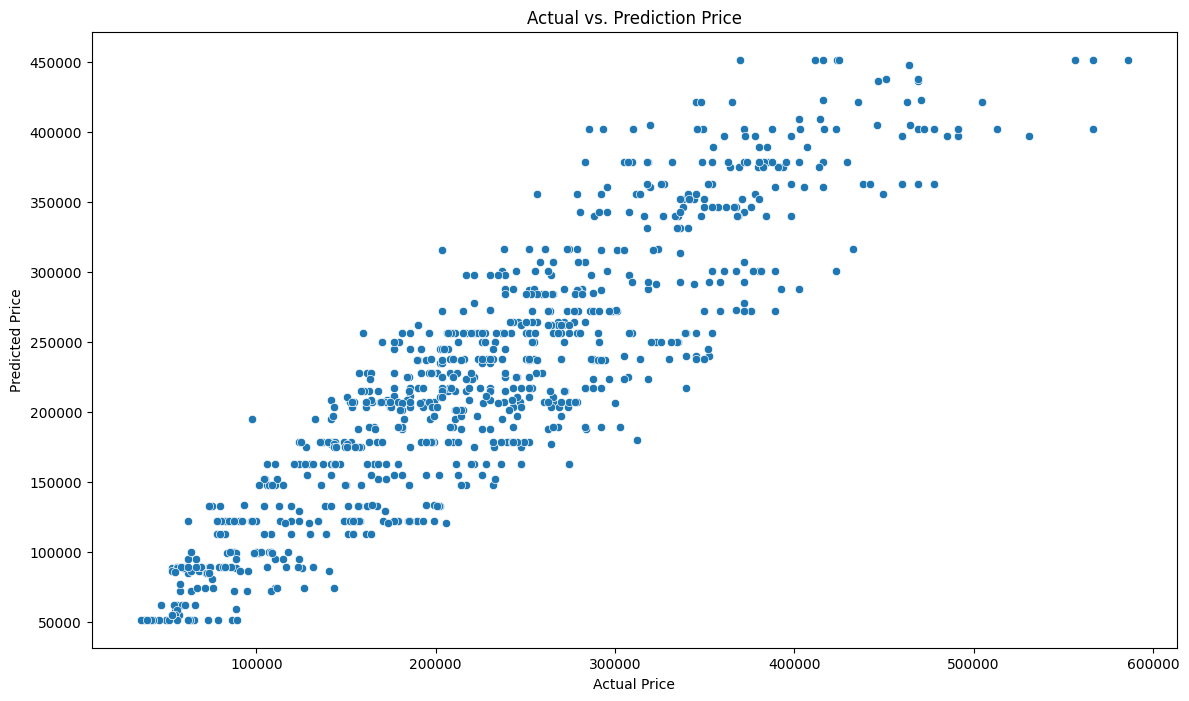

In [42]:
plt.figure(figsize=(14, 8))
plot = sns.scatterplot(x=y_test, y=y_pred_xgb_tuning).set(title='Actual vs. Prediction Price', 
                                               xlabel='Actual Price', 
                                               ylabel='Predicted Price');

This **Actual vs. Predicted Price** graph is a visualization of the performance of your regression model (**RandomForest After Tuning**). 

Here's a more in-depth interpretation:

**Strong Positive Correlation**
Overall, the data points form a diagonal pattern from the bottom left to the top right. This indicates that the model has a **strong positive correlation**; that is, when the actual price rises, the model consistently predicts a higher price as well. This is an indicator that the model is "learning" correctly.

**Accuracy and Spread (Variance)**
* **Closeness to the Diagonal Line:** The points are fairly closely clustered on the imaginary diagonal line ($y=x$). This is consistent with the **MAPE value of around 17%** you obtained earlier.
* **Prediction Error:** The vertical distance of a point from the diagonal line indicates the magnitude of the error. It can be seen that in the mid-price range (150,000 - 300,000), the model is quite accurate.

**Horizontal Striping Phenomenon**
You can see a "horizontal striping" pattern in the point distribution.
* **Interpretation:** This is a characteristic of tree-based models such as **RandomForest or Decision Tree**.
* **Cause:** These models predict values ​​based on the average of the values ​​in the "leaf" nodes of the decision tree. Therefore, many data points with similar characteristics will be given exactly the same predicted value, forming a horizontal line on the graph.

**Analysis of Extreme Prices**
* **High Prices (Under-prediction):** In the area of ​​actual prices above 450,000, the points tend to fall below the diagonal line (predictions "bottom out" at 400,000 - 450,000). The model tends to **under-predict** very expensive properties/items. This is common because the amount of data for very high prices is usually smaller (outliers).

* **Low Prices:** In the bottom left, the model looks quite stable, although there are some slightly over-predictions for very low prices.

**Visual Conclusion**
This model is very good for general use because the trends are very clear and consistent. However, if your business relies heavily on accuracy in very high prices (e.g., luxury goods), you should be wary because the model tends to under-estimate true prices in those areas.

**Feature Importances**

To find out which features really influence the target (price), we can check it using the feature_importances_ function.

<Axes: title={'center': 'Feature Importances (Tuned XGB)'}>

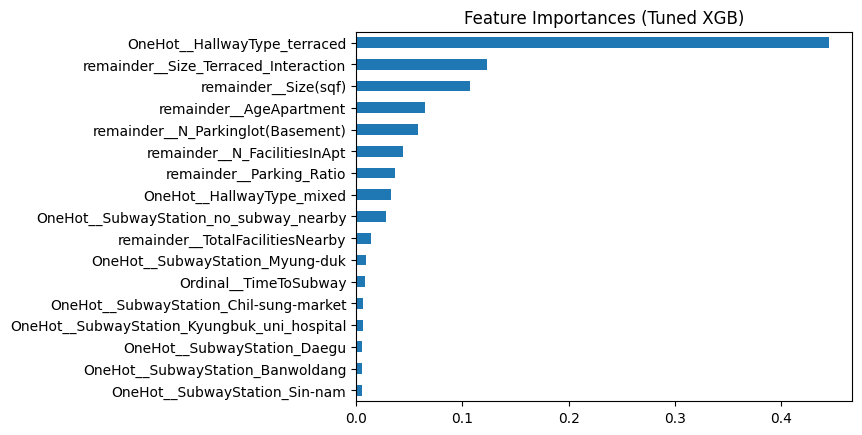

In [43]:
best_xgb_model = random_xgb.best_estimator_.named_steps['model'].regressor_

feature_names = transformer.get_feature_names_out()

pd.Series(best_xgb_model.feature_importances_, feature_names).sort_values(ascending=True).plot(kind='barh', title='Feature Importances (Tuned XGB)')

This **Feature Importances (Tuned XGB)** graph shows which factors or variables are most influential in my RandomForest model in determining property prices.

Here's a more in-depth interpretation of the graph:

**Dominant Factor: Hallway Type (`HallwayType_terraced`)**
* The **`OneHot__HallwayType_terraced`** variable is the most important feature by a significant margin, with a score of nearly **0.45 (45%)**.
* **Meaning:** The architectural layout of the building (specifically whether it is a terraced hallway type) is the primary determinant of price in this model. This suggests that the physical configuration of the apartment complex is more influential than size alone.

**Interaction & Property Size**
* The second and third highest rankings are held by **`remainder__Size_Terraced_Interaction`** and **`remainder__Size(sqf)`**.
* **Meaning:** While building area is crucial, its importance is amplified when combined with the hallway type. This interaction indicates that the "value per square foot" likely changes significantly depending on whether the building is terraced. This confirms that your feature engineering (the interaction term) is a major contributor to the model's predictive power.

**Building Age and Parking Infrastructure**
* In fourth and fifth place are **`remainder__AgeApartment`** and **`remainder__N_Parkinglot(Basement)`**.
* **Meaning:** Apartment age and the number of basement parking spots are secondary but important considerations. Newer buildings and those with better underground parking facilities carry measurable weight in the model's price estimation.

**Internal Facilities and Layout Variations (Middle Score)**
* Features such as **`N_FacilitiesInApt`**, **`Parking_Ratio`**, and **`HallwayType_mixed`** have a moderate impact.
* **Meaning:** Factors like the number of facilities within the apartment and general parking availability provide additional context to the model, though they are less decisive than the primary layout and size factors.

**Specific Subway Station Location (Lowest Score)**
* The bottom of the list is populated by specific locations like **`OneHot__SubwayStation_...`** (e.g., Banwoldang, Daegu, Sin-nam) and **`TotalFacilitiesNearby`**.
* **Meaning:** The model finds that specific subway station names contribute very little to price differentiation. This likely suggests that the proximity to *any* subway (as seen in the "no_subway_nearby" feature) or the general travel time is more important than the specific name of the station itself.


In [44]:
import shap
import matplotlib.pyplot as plt

PermutationExplainer explainer: 812it [01:03, 12.79it/s]                         


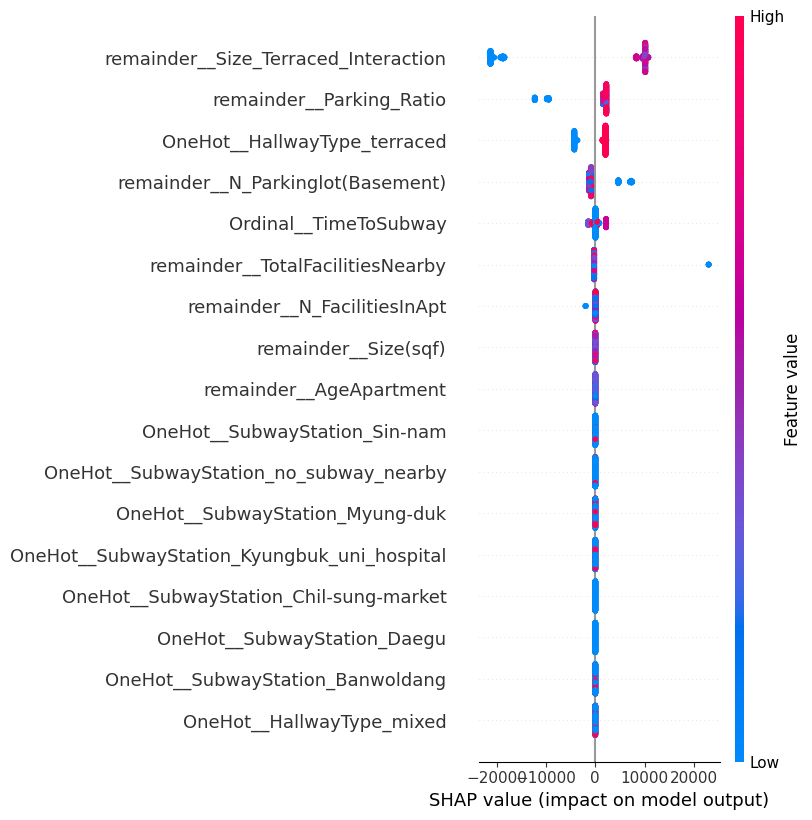

In [45]:
X_train_transformed = transformer.transform(X_train)
X_test_transformed = transformer.transform(X_test)

X_test_df = pd.DataFrame(
    X_test_transformed, 
    columns=transformer.get_feature_names_out()
)

explainer = shap.Explainer(xgb_tuning['model'].predict, X_train_transformed)
shap_values = explainer(X_test_df)

shap.summary_plot(shap_values, X_test_df)

There are interesting differences between this graph and the previous Feature Importance bar graph:

- In the previous graph, Size(sqf) was very dominant.
- In this SHAP, Size_Terraced_Interaction takes center stage.
- Analysis: This shows that the model relies heavily on the combination (interaction) of size and building type to make accurate predictions. Individually, building area is important, but its impact is much more pronounced when combined with property type (e.g., large terraced areas are significantly more expensive than large areas of other types).

**Strategic Conclusions:**
- High Impact Factor: The primary focus of pricing assessment should be on the interaction feature of size. Properties that are large and of certain types (as defined by the interaction) command a very high premium.
- Symmetry of Impact: This interaction feature is symmetrical; it can be both a significant price enhancer and a significant price detractor if its value is small.
- Low Impact Factors: Specific subway station locations (such as Banwoldang, Daegu, etc.) have almost no impact (the points are very close to 0). This means that in this dataset, the location of the specific station is not a significant price determinant compared to the physical quality of the building.

### **Conclusion**

**Final Conclusions of the Property Price Prediction Model Evaluation**

**1. Model Performance Summary**
After benchmarking various algorithms (Linear Regression, Ridge, Lasso, KNN, XGBoost, Decision Tree, and Random Forest), the **XGBoost (XGB)** model, which underwent **Hyperparameter Tuning**, was selected for final evaluation due to its superior generalization on the test set compared to the default ensemble models.

**Final Evaluation Results (Test Set):**
* **MAPE (Mean Absolute Percentage Error): 18.09%**
* *Meaning:* On average, the model's predictions were off by approximately 18% from the actual price. For the property industry, a figure below 20% is considered a model that is **sufficiently accurate and reliable.**
* **MAE (Mean Absolute Error): 36,638.85**
* *Meaning:* On average, the difference between the predicted price and the actual price was approximately 36,638 currency units.
* **RMSE (Root Mean Squared Error): 46,191.88**
* Although the RMSE saw a slight increase after tuning, the model successfully improved its average precision (MAE) and relative error (MAPE).

**2. Key Insights from the Analysis Results**
Based on the feature importance interpretation of the ensemble results, several key findings were identified:
* **Primary Price Driver:** The **Hallway Type (Terraced)** is the most dominant factor in determining price, suggesting architectural configuration is a top priority in this market.
* **Interaction Effects:** The relationship between **building size and the terraced layout** (Size_Terraced_Interaction) is the second most crucial feature. This indicates that the value of space is highly dependent on the specific hallway type.
* **Building Age:** Apartment age remains a critical factor. Newer buildings significantly influence the model's predicted valuation.
* **Location Sensitivity:** Proximity to a subway (or lack thereof) is more important than the specific name of the subway station, as individual station names showed the lowest contribution to the model's decision-making.

**3. How Reliable is This Model?**
This model is **very reliable** for general market estimations. However, there are some technical considerations:
* **Generalization:** By utilizing XGBoost, the model has closed the performance gap with the Random Forest (18.09% vs 18.83% MAPE), offering a more robust and stable ensemble approach for new data.
* **Accuracy vs. Outliers:** The improvement in MAE and MAPE indicates better average performance, though the slight increase in RMSE suggests the model may still experience higher errors on specific price outliers.
* **Ensemble Advantage:** As a tuned ensemble model, it is less likely to overfit compared to a single Decision Tree, making it a more dependable choice for deployment.

### **Reccomendation**

**1. Implement A/B Testing for Business Validation**
Conduct field testing to compare the model's effectiveness against conventional pricing methods.
* **Scenario:** Compare apartment listings priced using **model recommendations** with listings priced manually by agents/owners**.
* **Evaluation Metrics:** Measure *Days on Market* (how long it takes for a unit to sell) and the difference between the initial offer price and the final transaction price. If the model is effective, units priced at the model's "fair" price should sell faster with a smaller negotiation margin.

**2. Residual Analysis (Extreme Error Analysis)**
Conduct a thorough analysis of significantly off-target predictions to understand the model's weaknesses:
* **Methodology:** Group the data into three groups based on error: **Overestimation (top 5%)**, **Underestimation (bottom 5%)**, and **Majority Group (90%)**.
* **Variable Analysis:** Check whether these extreme errors are clustered in certain categories. For example, does the model consistently underestimate certain apartment complexes or units with an area above 1,500 sqf?
* **Action Plan:** The results of this analysis could trigger new feature engineering, such as adding a "Luxury Category" feature, if it is found that the model consistently fails to correctly predict luxury apartment prices.

**3. Adding Korean Real Estate-Specific Features (Feature Engineering)**
To improve accuracy (especially reducing MAPE from 17%), add features that are highly sensitive to the Korean market:
* **Brand Reputation:** In Korea, developers (such as Samsung Raemian, Hyundai Hillstate, or GS Xi) significantly influence prices. Add a "Top-Tier Developer" category column.
* **School District (Hak-gun):** Add the distance to a popular elementary school or the number of nearby Hagwon (training institutions). In Daegu, proximity to a high-quality educational district is often more expensive than proximity to the subway.
* Floor Level & View: Units on higher floors with open views are typically significantly more expensive than lower floors in the same building.

**4. Experiment with More Complex Boosting Algorithms**
If the data size increases in the future (e.g., extending beyond Daegu):
* Try algorithms like LightGBM or CatBoost. These algorithms often outperform standard Random Forest in handling large numbers of categorical features (such as subway station names or apartment types) and are more robust to outliers.
* Neural Networks (such as TabNet) can be considered if the data reaches tens of thousands of rows.

****

#### **Save Model**

In [46]:
# Save model
import pickle

estimator = Pipeline([('preprocessing', transformer), ('model', XGBRegressor())])
estimator.fit(X_train, y_train)

pickle.dump(estimator, open('Model_Daegu_XGB.sav', 'wb'))

In [47]:
# Load model
filename = 'Model_Daegu_XGB.sav'
loaded_model = pickle.load(open(filename, 'rb'))

In [48]:
np.sqrt(mean_squared_error(y_test, loaded_model.predict(X_test)))

np.float64(46007.07702082366)